In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [5]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename):
    return (uproot.open(filename)["MatchedTree"]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

# 2023 embedding

In [15]:
observables1 = ['pt','b','w']
observabless1 = ['pts','bs',"ws"]
df_reco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root'),\
              'pts>15 and bs!=-9 and bs!=0')

In [14]:
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(['pt','b'], library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9')
df_data['w'] = np.ones(df_data.shape[0])
df_data['ws'] = np.ones(df_data.shape[0])

In [16]:
df_reco_pts_array = [ df_reco[(df_reco.pts>15) & (df_reco.pts<20)],\
                       df_reco[(df_reco.pts>20) & (df_reco.pts<25)],\
                       df_reco[(df_reco.pts>25) & (df_reco.pts<30)],\
                       df_reco[(df_reco.pts>30) & (df_reco.pts<40)],\
                       df_reco[(df_reco.pts>40) & (df_reco.pts<60)] ]
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [17]:
rc_reco_bs_vs_pts_array = []
rc_err_reco_bs_vs_pts_array = []
for i in range(0, len(df_reco_pts_array)):
    rc_reco_bs_vs_pts_array.append(getRcAndErr(df_reco_pts_array[i], 'bs')[0])
    rc_err_reco_bs_vs_pts_array.append(getRcAndErr(df_reco_pts_array[i], 'bs')[1])

rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErr(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErr(df_data_pts_array[i], 'bs')[1])

/tmp/ipykernel_2743622/104127035.py:41: RuntimeWarning: invalid value encountered in sqrt
  rc_err = 2*np.sqrt(sum(err2_array))


In [19]:
plt.rcParams['font.size'] = 12

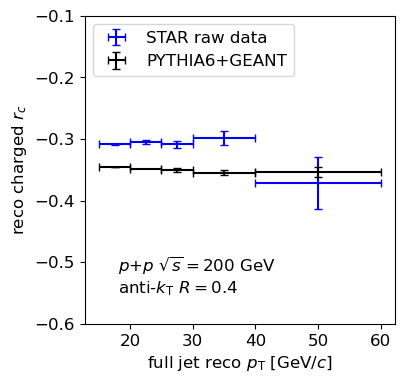

In [22]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='b', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_reco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_reco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='PYTHIA6+GEANT')
plt.text(18, -0.55, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ $R = 0.4$')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

# 2015 embedding

In [4]:
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0415_pt10_m0_new.root')
tree = file["ResultTree"].arrays(['pt','b'], library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9')
df_data['w'] = np.ones(df_data.shape[0])
df_data['ws'] = np.ones(df_data.shape[0])

In [6]:
observables1 = ['pt','b','dr','z','epair','w','reject','pid1','pid2','pt1','pt2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pid1s','pid2s','pt1s','pt2s']
df_reco = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/other_output/rc/all0615.root',\
                              "MatchedTree"), 'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [25]:
df_reco_pts_array = [ df_reco[(df_reco.pts>15) & (df_reco.pts<20)],\
                       df_reco[(df_reco.pts>20) & (df_reco.pts<25)],\
                       df_reco[(df_reco.pts>25) & (df_reco.pts<30)],\
                       df_reco[(df_reco.pts>30) & (df_reco.pts<40)],\
                       df_reco[(df_reco.pts>40) & (df_reco.pts<60)] ]
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [26]:
rc_reco_bs_vs_pts_array = []
rc_err_reco_bs_vs_pts_array = []
for i in range(0, len(df_reco_pts_array)):
    rc_reco_bs_vs_pts_array.append(getRcAndErr(df_reco_pts_array[i], 'bs')[0])
    rc_err_reco_bs_vs_pts_array.append(getRcAndErr(df_reco_pts_array[i], 'bs')[1])

rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErr(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErr(df_data_pts_array[i], 'bs')[1])

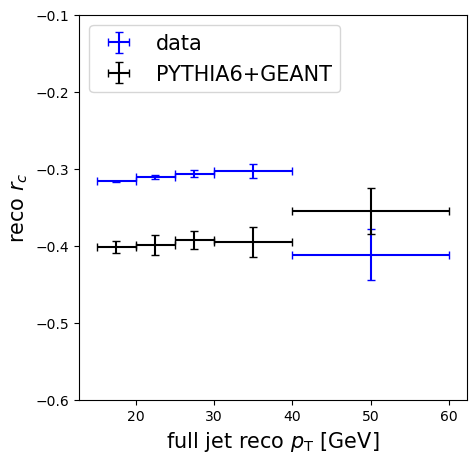

In [27]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='b', ls='none', label='data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_reco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_reco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='PYTHIA6+GEANT')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco $r_c$', fontsize=15)
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left', fontsize=15)

In [28]:
observables1 = ['pt','b','w','reject','pt1','pt2','y1','y2','phi1','phi2','nef','evid']
observabless1 = ['pts','bs','ws','rejects','pt1s','pt2s','y1s','y2s','phi1s','phi2s','nefs','evids']
df_reco = applyCut(getData(observables1+observabless1, '/gpfs/gibbs/project/havener/ys668/other_output/rc/all0615_final.root',\
                              "MatchedTree"), 'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [32]:
file = uproot.open('/gpfs/gibbs/project/havener/ys668/other_output/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(['pt','b'], library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9')
df_data['w'] = np.ones(df_data.shape[0])
df_data['ws'] = np.ones(df_data.shape[0])

In [33]:
df_reco_pts_array = [ df_reco[(df_reco.pts>15) & (df_reco.pts<20)],\
                       df_reco[(df_reco.pts>20) & (df_reco.pts<25)],\
                       df_reco[(df_reco.pts>25) & (df_reco.pts<30)],\
                       df_reco[(df_reco.pts>30) & (df_reco.pts<40)],\
                       df_reco[(df_reco.pts>40) & (df_reco.pts<60)] ]
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [34]:
rc_reco_bs_vs_pts_array = []
rc_err_reco_bs_vs_pts_array = []
for i in range(0, len(df_reco_pts_array)):
    rc_reco_bs_vs_pts_array.append(getRcAndErr(df_reco_pts_array[i], 'bs')[0])
    rc_err_reco_bs_vs_pts_array.append(getRcAndErr(df_reco_pts_array[i], 'bs')[1])

rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErr(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErr(df_data_pts_array[i], 'bs')[1])

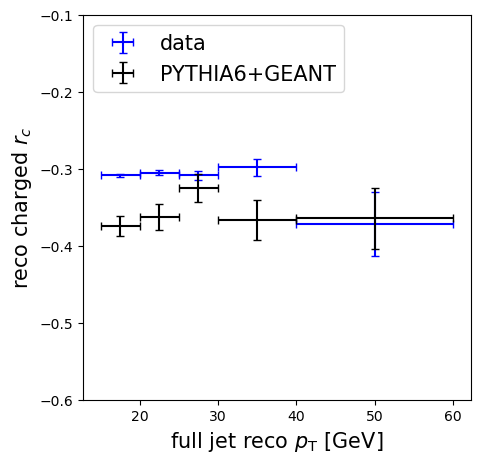

In [35]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='b', ls='none', label='data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_reco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_reco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='PYTHIA6+GEANT')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged $r_c$', fontsize=15)
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left', fontsize=15)